# TP N°1 : Apprentissage supervisé avec Scikit-learn
## Exercice 1 : Régression, prédiction du tarif d'un trajet Uber

**Module :** Technologies IA | **Filière :** ILIA2, ENSA Fès
**Réalisé par :** Ben Abbou Ahlame  **N : 6
 et ** Barbara Kawtar : **N : 5

**Objectif :** prédire le prix d'un trajet Uber (`fare_amount`) à partir de la distance, de l'heure, du jour de la semaine et du nombre de passagers.

**Modèles comparés :** Régression linéaire et Random Forest.

## 0. Importation des bibliothèques

## Étape 1 : Chargement et exploration du jeu de données
### 1.1 Chargement du fichier CSV
On charge `uber.csv` avec pandas et on affiche les premières lignes.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
data = pd.read_csv('uber.csv')
data.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


### 1.2 Informations sur les colonnes et valeurs manquantes
On vérifie les types de variables, la taille du jeu de données et le nombre de valeurs manquantes par colonne.

In [ ]:
print(data.info())
print("\nValeurs manquantes :")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None

Valeurs manquantes :
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


### 1.3 Statistiques descriptives
Elles permettent de repérer les valeurs aberrantes (prix négatifs, coordonnées GPS à 0, nombre de passagers égal à 0, etc.).

In [ ]:
data.describe()


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


**Observations :**
- Le jeu de données contient 200 000 trajets. Seule 1 ligne a des valeurs manquantes (coordonnées d'arrivée `dropoff_longitude` et `dropoff_latitude`).
- `fare_amount` contient des valeurs aberrantes : un minimum négatif (-52 $), ce qui est impossible, et un maximum de 499 $, très éloigné de la médiane (8,5 $).
- `passenger_count` va de 0 à 208 : les valeurs 0 et supérieures à 6 sont irréalistes.
- Les coordonnées GPS contiennent des valeurs impossibles (latitude jusqu'à 1644, longitude jusqu'à -3356) ainsi que des points à 0, qui sont hors de New York.
- La colonne `Unnamed: 0` est un simple identifiant et ne sera pas utilisée.
- Il n'existe pas de colonne `distance` : il faudra la calculer à partir des coordonnées.

**Conclusion de l'exploration :** un nettoyage rigoureux est indispensable avant d'entraîner les modèles, sinon ces valeurs aberrantes fausseraient fortement les résultats.

## Étape 2 : Nettoyage et préparation des données
### 2.1 Suppression des valeurs manquantes

In [ ]:
print("Avant :", data.shape)
data = data.dropna()
print("Après  :", data.shape)

Avant : (200000, 9)
Après  : (199999, 9)


### 2.2 Suppression des valeurs aberrantes
- Prix : on garde les tarifs strictement positifs et inférieurs à 200 $.
- Passagers : entre 1 et 6.
- Coordonnées GPS : on supprime les points à 0 ou hors de la zone de New York.

In [ ]:
data = data[(data['fare_amount'] > 0) & (data['fare_amount'] < 200)]
data = data[(data['passenger_count'] > 0) & (data['passenger_count'] <= 6)]

data = data[(data['pickup_latitude'].between(40, 42)) &
            (data['dropoff_latitude'].between(40, 42)) &
            (data['pickup_longitude'].between(-75, -72)) &
            (data['dropoff_longitude'].between(-75, -72))]

print("Taille après nettoyage :", data.shape)

Taille après nettoyage : (195095, 9)


### 2.3 Création de la variable `distance`
Le jeu de données ne contient pas de colonne distance. On la calcule à partir des coordonnées GPS de départ et d'arrivée avec la **formule de Haversine** (distance en km à la surface de la Terre).

In [ ]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # rayon de la Terre en km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

data['distance'] = haversine(data['pickup_latitude'], data['pickup_longitude'],
                             data['dropoff_latitude'], data['dropoff_longitude'])

# On supprime les distances nulles ou irréalistes
data = data[(data['distance'] > 0) & (data['distance'] < 100)]
data['distance'].describe()

,distance
count,193055.000000
mean,3.362345
std,3.726535
min,0.000084
25%,1.280591
50%,2.180692
75%,3.939609
max,99.162509


### 2.4 Création des variables temporelles
À partir de `pickup_datetime`, on extrait l'heure (`hour`) et le jour de la semaine (`day_of_week`, 0 = lundi, 6 = dimanche).

In [ ]:
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek
data[['pickup_datetime', 'hour', 'day_of_week', 'distance', 'fare_amount']].head()

,pickup_datetime,hour,day_of_week,distance,fare_amount
0,2015-05-07 19:52:06+00:00,19,3,1.683323,7.5
1,2009-07-17 20:04:56+00:00,20,4,2.457590,7.7
2,2009-08-24 21:45:00+00:00,21,0,5.036377,12.9
3,2009-06-26 08:22:21+00:00,8,4,1.661683,5.3
4,2014-08-28 17:47:00+00:00,17,3,4.475450,16.0


### 2.5 Visualisation rapide : relation distance et tarif

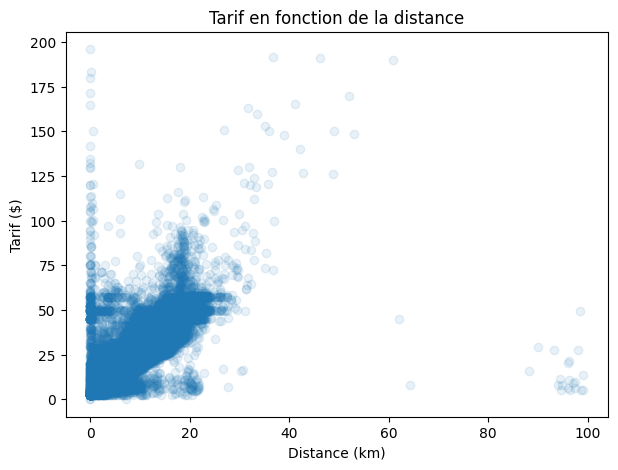

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(data['distance'], data['fare_amount'], alpha=0.1)
plt.xlabel('Distance (km)')
plt.ylabel('Tarif ($)')
plt.title('Tarif en fonction de la distance')
plt.show()

**Observation :**
- Le tarif augmente globalement avec la distance : la relation est approximativement linéaire jusqu'à environ 20 km, ce qui justifie l'utilisation de la distance comme variable explicative principale.
- On observe un palier horizontal autour de 50-55 $ pour des distances de 10 à 25 km, probablement dû à des tarifs forfaitaires (par exemple vers les aéroports). Une relation purement linéaire ne peut pas bien le capturer.
- Une colonne de points apparaît à distance proche de 0 km avec des tarifs allant jusqu'à 200 $ : il s'agit soit de trajets aller-retour, soit d'erreurs de coordonnées GPS. La distance en ligne droite (Haversine) sous-estime aussi la distance réellement parcourue.
- Quelques points isolés à plus de 90 km avec des tarifs faibles sont incohérents et correspondent probablement à des erreurs de saisie.
- Ces anomalies indiquent que le Random Forest, capable de modéliser des relations non linéaires, devrait mieux s'en sortir que la régression linéaire.

## Étape 3 : Séparation des données
On choisit les variables explicatives (X) et la cible (y), puis on sépare **80 % pour l'entraînement** et **20 % pour le test**.

In [ ]:
X = data[['distance', 'hour', 'day_of_week', 'passenger_count']]
y = data['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)

Train : (154444, 4)
Test  : (38611, 4)


## Étape 4 : Entraînement du modèle de régression linéaire

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

## Étape 5 : Évaluation du modèle linéaire
Métriques utilisées :
- **MAE** : erreur absolue moyenne (en $)
- **RMSE** : racine de l'erreur quadratique moyenne (pénalise les grosses erreurs)
- **R²** : proportion de variance expliquée (plus proche de 1 = meilleur)

In [ ]:
def evaluer(nom, y_true, y_pred):
    print(f"--- {nom} ---")
    print('MAE  =', round(mean_absolute_error(y_true, y_pred), 3))
    print('RMSE =', round(np.sqrt(mean_squared_error(y_true, y_pred)), 3))
    print('R²   =', round(r2_score(y_true, y_pred), 3))

evaluer("Régression linéaire", y_test, y_pred)

--- Régression linéaire ---
MAE  = 2.388
RMSE = 5.346
R²   = 0.689


## Étape 6 : Amélioration avec Random Forest
Le Random Forest combine plusieurs arbres de décision et peut capturer des relations **non linéaires**. L'entraînement peut prendre 1 à 2 minutes.

In [ ]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

evaluer("Random Forest", y_test, y_pred_rf)

--- Random Forest ---
MAE  = 2.465
RMSE = 4.716
R²   = 0.758


### Comparaison des deux modèles

In [ ]:
resultats = pd.DataFrame({
    'Modèle': ['Régression linéaire', 'Random Forest'],
    'MAE':  [mean_absolute_error(y_test, y_pred),  mean_absolute_error(y_test, y_pred_rf)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred)), np.sqrt(mean_squared_error(y_test, y_pred_rf))],
    'R²':   [r2_score(y_test, y_pred), r2_score(y_test, y_pred_rf)]
}).round(3)
resultats

,Modèle,MAE,RMSE,R²
0,Régression linéaire,2.388,5.346,0.689
1,Random Forest,2.465,4.716,0.758


## Étape 7 : Visualisation des résultats
### 7.1 Valeurs réelles vs valeurs prédites (Random Forest)
Plus les points sont proches de la droite rouge, meilleure est la prédiction.

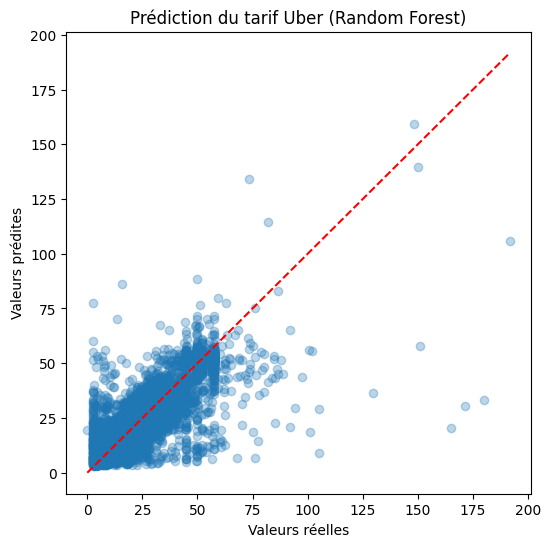

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Prédiction du tarif Uber (Random Forest)')
plt.show()

### 7.2 Importance des variables
Quelles variables influencent le plus le tarif selon le Random Forest ?

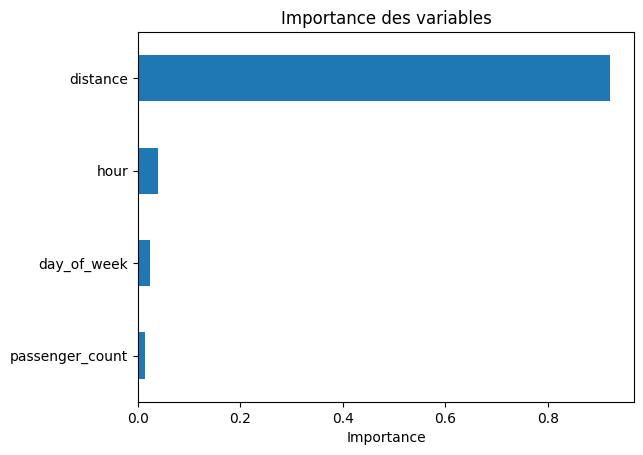

In [ ]:
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind='barh')
plt.title('Importance des variables')
plt.xlabel('Importance')
plt.show()

## Conclusion

**Résultats :**

| Modèle | MAE | RMSE | R² |
|---|---|---|---|
| Régression linéaire | 2.388	 |5.346	 | 0.689 |
| Random Forest | 2.465 | 4.716 | 0.758 |

**Interprétation :**
- Le Random Forest prédit le tarif avec une erreur moyenne d'environ 2,5 $ et explique 76 % de la variance.
- La distance est la variable la plus importante (environ 90 %), car le prix dépend surtout de la longueur du trajet. L'heure, le jour et le nombre de passagers jouent très peu.
- Limites : la distance est calculée en ligne droite, et on n'a pas la météo, le trafic ni le quartier.

**Modèle retenu :** le Random Forest, car il a une erreur plus faible et un meilleur R² que la régression linéaire.

# TP1 — Exercice 2 : Classification — Survie sur le Titanic


**Objectif :** prédire si un passager a survécu (1) ou non (0).

**Données :** `train.csv` de la compétition Kaggle *Titanic* (à renommer en `titanic.csv` ou à adapter le chemin ci-dessous).

0. Importation des bibliothèques

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Étape 1 : Chargement et exploration


## Étape 1 : Chargement et exploration du jeu de données
### 1.1 Chargement du fichier CSV
On charge `Titanic.csv` avec pandas et on affiche les premières lignes.
Étape 1 : Chargement et exploration du jeu de données
1.1 Chargement du fichier CSV
On charge Titanic.csv avec pandas et on affiche les premières lignes.

In [ ]:
import pandas as pd

data = pd.read_csv('Titanic-Dataset.csv')

data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1.2 Informations sur les colonnes et valeurs manquantes
On vérifie les types de variables, la taille du jeu de données et le nombre de valeurs manquantes par colonne.

In [ ]:
print(data.info())
print("\nValeurs manquantes: ")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Valeurs manquantes: 
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked

### 1.3 Statistiques descriptives
Elles permettent de repérer les valeurs aberrantes (prix négatifs, coordonnées GPS à 0, nombre de passagers égal à 0, etc.).

In [ ]:
print(data.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


## Observations : nettoyage des données

### 1. Valeurs manquantes

| Colonne | Valeurs manquantes | Décision |
|---|---|---|
| `Age` | 177 sur 891 (≈ 20 %) | remplacée par la **médiane** (28 ans) |
| `Embarked` | 2 | remplacées par le **mode** (port le plus fréquent) |
| `Cabin` | ≈ 687 (≈ 77 %) | colonne **supprimée** (trop incomplète) |

**Justification :** la médiane est moins sensible aux valeurs extrêmes que la moyenne. Supprimer les lignes avec `Age` manquant ferait perdre 20 % des données.

### 2. Colonnes supprimées

- `PassengerId` : simple identifiant, sans pouvoir prédictif.
- `Name` et `Ticket` : texte libre, difficile à exploiter sans transformation.
- `Cabin` : trop de valeurs manquantes.

### 3. Valeurs aberrantes

- Aucune valeur négative ou impossible dans `Age`, `SibSp`, `Parch` et `Pclass`.
- `Fare = 0` : suspect mais plausible (billets gratuits, équipage).
- `Fare` max = 512,33 : valeur extrême mais réelle. La distribution est asymétrique (moyenne 32,2 > médiane 14,45).
- **Décision :** aucune ligne supprimée, car ces valeurs correspondent à des cas réels. Le Random Forest est peu sensible aux valeurs extrêmes, et la régression logistique est aussi testée avec `StandardScaler`.


Étape 2 : Nettoyage et préparation des données

2.1 les valeurs manquantes

In [ ]:
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])


print(data.head())
print(data.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Pa

2.2 les colonnes unitiles


In [ ]:
data = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], errors='ignore')

print("Colonnes restantes :", data.columns.tolist())
print("Dimensions après suppression :", data.shape)

Colonnes restantes : ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Dimensions après suppression : (891, 8)


### Colonnes supprimées

| Colonne | Raison de la suppression |
|---|---|
| `PassengerId` | simple identifiant, sans pouvoir prédictif |
| `Name` | texte unique pour chaque passager, inexploitable tel quel |
| `Ticket` | codes quasi uniques, sans structure exploitable |
| `Cabin` | environ 77 % de valeurs manquantes |

**Limite :** `Name` contient une information utile, le titre (Mr, Mrs, Miss, Master...), qui pourrait être extraite comme amélioration future.

3.3 les valeurs aberrantes


In [ ]:
# 1. Valeurs impossibles ou suspectes
print("Age min / max :", data['Age'].min(), "/", data['Age'].max())
print("Valeurs négatives dans Fare :", (data['Fare'] < 0).sum())
print("Fare = 0 :", (data['Fare'] == 0).sum(), "passagers")
print("SibSp max :", data['SibSp'].max(), "| Parch max :", data['Parch'].max())


Age min / max : 0.42 / 80.0
Valeurs négatives dans Fare : 0
Fare = 0 : 15 passagers
SibSp max : 8 | Parch max : 6


## Étape 3 : Encodage des variables catégorielles

| Colonne | Valeurs d'origine | Encodage obtenu |
|---|---|---|
| `Sex` | female, male | female = 0, male = 1 |
| `Embarked` | C, Q, S | C = 0, Q = 1, S = 2 |

**Pourquoi :** les modèles scikit-learn n'acceptent que des valeurs numériques.

**Limite :** `LabelEncoder` impose un ordre artificiel à `Embarked` (C < Q < S), que la régression logistique peut interpréter comme une quantité. Le Random Forest y est peu sensible. Pour `Sex`, qui n'a que 2 valeurs, il n'y a pas de problème.

In [ ]:
from sklearn.preprocessing import LabelEncoder

le_sex = LabelEncoder()
le_emb = LabelEncoder()

data['Sex'] = le_sex.fit_transform(data['Sex'])
data['Embarked'] = le_emb.fit_transform(data['Embarked'])

print("Sex      :", dict(zip(le_sex.classes_, le_sex.transform(le_sex.classes_))))
print("Embarked :", dict(zip(le_emb.classes_, le_emb.transform(le_emb.classes_))))
print()
print(data.dtypes)
data.head()

Sex      : {'female': np.int64(0), 'male': np.int64(1)}
Embarked : {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}

Survived      int64
Pclass        int64
Sex           int64
Age         float64
SibSp         int64
Parch         int64
Fare        float64
Embarked      int64
dtype: object


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


## Étape 4 : Séparation des données

- **Variables explicatives (`X`)** : 7 colonnes (`Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`).
- **Cible (`y`)** : `Survived` (0 = décédé, 1 = survivant).
- **Découpage** : 80 % entraînement (712 passagers), 20 % test (179 passagers).
- **`random_state=42`** : garantit la reproductibilité des résultats.
- **`stratify=y`** : conserve la proportion de survivants (≈ 38 %) dans les deux ensembles, ce qui est important car les classes sont déséquilibrées.

**Limite :** l'imputation de `Age` (médiane) a été calculée sur toutes les données avant le découpage. Une version plus rigoureuse la calculerait uniquement sur `X_train`, pour éviter qu'une information du test ne passe dans l'entraînement (*data leakage*). Sur ce jeu de données, l'effet est négligeable.



In [ ]:
from sklearn.model_selection import train_test_split

X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (712, 7)
X_test  : (179, 7)
y_train : (712,)
y_test  : (179,)


## Étape 5 : Entraînement des modèles

Deux modèles sont entraînés sur les mêmes données (`X_train`, `y_train`) :

- **Régression logistique** (`max_iter=1000`) : modèle linéaire, simple et interprétable.
- **Random Forest** (`n_estimators=100`, `random_state=42`) : ensemble de 100 arbres de décision combinés par vote, capable de capter des relations non linéaires.

**Observations (à adapter à vos résultats) :**
- Les coefficients de la régression logistique montrent que `Sex` et `Pclass` ont l'influence négative la plus forte sur la survie.
- Le Random Forest classe `Sex`, `Fare` et `Age` parmi les variables les plus importantes.
- Le score élevé du Random Forest sur l'entraînement ne suffit pas à conclure : l'évaluation sur le test (étape 6) permettra de juger.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

regarder ce que les modèles ont appris

In [ ]:
# Régression logistique : poids de chaque variable
coef = pd.Series(log_model.coef_[0], index=X_train.columns).sort_values()
print(coef.round(3))

# Random Forest : importance de chaque variable
imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.round(3))

Sex        -2.590
Pclass     -1.046
SibSp      -0.247
Embarked   -0.231
Parch      -0.087
Age        -0.038
Fare        0.002
dtype: float64
Fare        0.270
Sex         0.261
Age         0.250
Pclass      0.093
SibSp       0.050
Parch       0.041
Embarked    0.035
dtype: float64


premier controle d apprentissage

In [ ]:
print("Accuracy entraînement (Logistic) :", round(log_model.score(X_train, y_train), 3))
print("Accuracy entraînement (RF)       :", round(rf_model.score(X_train, y_train), 3))

Accuracy entraînement (Logistic) : 0.802
Accuracy entraînement (RF)       : 0.982


## Étape 6 : Évaluation des modèles

Les deux modèles sont évalués sur l'ensemble de test (179 passagers, jamais vus pendant l'entraînement).

| Modèle | Accuracy test | Précision (survivants) | Rappel (survivants) | F1 (survivants) |
|---|---|---|---|---|
| Régression logistique | ... | ... | ... | ... |
| Random Forest | ... | ... | ... | ... |

**Observations (à compléter avec vos résultats) :**
- Quel modèle a la meilleure accuracy ? L'écart est-il significatif ou faible ?
- Quel modèle retrouve le mieux les survivants (rappel de la classe 1) ?
- Y a-t-il du surapprentissage (grand écart entre le score d'entraînement et le score de test) ?
- Les classes sont déséquilibrées (≈ 62 % de décès) : l'accuracy seule ne suffit pas, d'où l'analyse de la précision, du rappel et du F1.

### Predictions et accurancy

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print('Accuracy (Logistic)     :', round(accuracy_score(y_test, y_pred_log), 3))
print('Accuracy (Random Forest):', round(accuracy_score(y_test, y_pred_rf), 3))

Accuracy (Logistic)     : 0.804
Accuracy (Random Forest): 0.827


###rapports détaillés

In [ ]:
print('--- Régression logistique ---')
print(classification_report(y_test, y_pred_log))

print('--- Random Forest ---')
print(classification_report(y_test, y_pred_rf))

--- Régression logistique ---
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.84      0.89      0.86       110
           1       0.81      0.72      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



###comparaison avec l’entraînement (surapprentissage)

In [ ]:
print("Régression logistique : train =", round(log_model.score(X_train, y_train), 3),
      "| test =", round(log_model.score(X_test, y_test), 3))
print("Random Forest         : train =", round(rf_model.score(X_train, y_train), 3),
      "| test =", round(rf_model.score(X_test, y_test), 3))

Régression logistique : train = 0.802 | test = 0.804
Random Forest         : train = 0.982 | test = 0.827


## Étape 7 : Matrices de confusion

| Modèle | VN | FP | FN | VP | Erreurs totales |
|---|---|---|---|---|---|
| Régression logistique | ... | ... | ... | ... | ... |
| Random Forest | ... | ... | ... | ... | ... |

**Observations (à compléter avec vos résultats) :**
- Les deux modèles classent mieux les décédés que les survivants : la classe majoritaire (≈ 62 %) est plus facile à reconnaître.
- Quel modèle fait le moins de faux négatifs, c'est-à-dire rate le moins de survivants ?
- Quel modèle fait le moins de faux positifs ?
- Les erreurs des deux modèles sont-elles de même nature, ou l'un d'eux se trompe plutôt dans un sens ?

###Random Forest

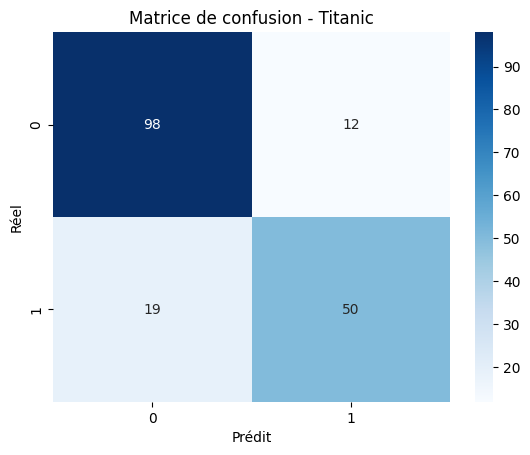

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()

###comparer les deux modèles côte à côte

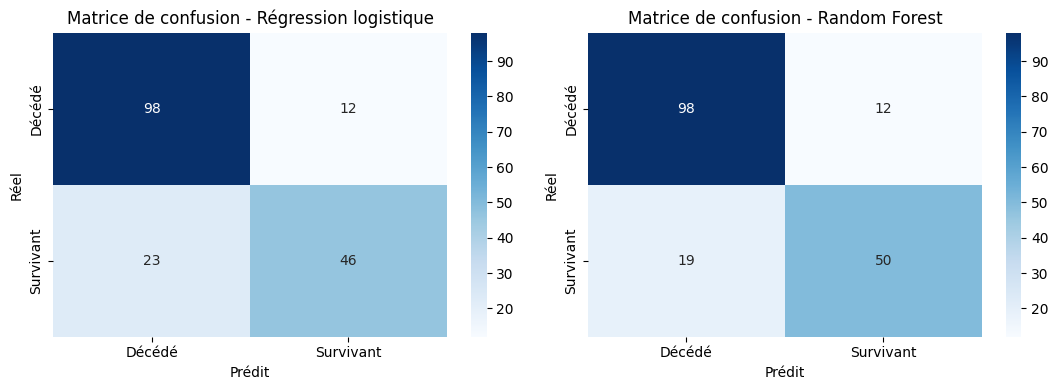

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pred, nom in zip(axes,
                         [y_pred_log, y_pred_rf],
                         ['Régression logistique', 'Random Forest']):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Décédé', 'Survivant'],
                yticklabels=['Décédé', 'Survivant'])
    ax.set_title(f'Matrice de confusion - {nom}')
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()

###Extraire les chiffres

In [ ]:
for nom, pred in [('Régression logistique', y_pred_log), ('Random Forest', y_pred_rf)]:
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    print(f"{nom}")
    print(f"  Vrais négatifs : {vn} | Faux positifs : {fp}")
    print(f"  Faux négatifs  : {fn} | Vrais positifs : {vp}")
    print(f"  Erreurs totales : {fp + fn} sur {len(y_test)}\n")

Régression logistique
  Vrais négatifs : 98 | Faux positifs : 12
  Faux négatifs  : 23 | Vrais positifs : 46
  Erreurs totales : 35 sur 179

Random Forest
  Vrais négatifs : 98 | Faux positifs : 12
  Faux négatifs  : 19 | Vrais positifs : 50
  Erreurs totales : 31 sur 179

